In [17]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_circles
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X, y = make_circles(n_samples=500, noise=0.05, factor=0.5, random_state=42)

print(f"Data shape: {X.shape}, Labels shape: {y.shape}")
print(f"First 5 samples:\n{X[:5, :1]}\nLabels:\n{y[:5]}")



Data shape: (500, 2), Labels shape: (500,)
First 5 samples:
[[-0.46927625]
 [-0.16416437]
 [-0.47145368]
 [-0.67034684]
 [-0.82646813]]
Labels:
[1 0 1 0 0]


In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
print(f"Training samples: {X_train.shape}, Testing samples: {X_test.shape}")
print(f"First 5 training samples:\n{X_train[:5, :1]}\nLabels:\n{y_train[:5]}")

model = SVC(
  kernel='rbf',
  C=1.0 , gamma='scale')
model.fit(X_train, y_train)

def plot_decision_boundary(model, X, y):
  h = .02
  x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
  y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
  
  xx , yy = np.meshgrid(np.arange(x_min, x_max, h) , np.arange(y_min, y_max, h))
  Z = model.predict(np.c_[xx.ravel() , yy.ravel()])
  Z = Z.reshape(xx.shape)
  
  plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.coolwarm)
  plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap=plt.cm.coolwarm)
  plt.title("SVM with RBF Kernel (Non-Linear)")
  plt.show()

Training samples: (400, 2), Testing samples: (100, 2)
First 5 training samples:
[[ 0.09250543]
 [ 0.16415232]
 [-1.02234609]
 [ 0.22442169]
 [ 0.23339144]]
Labels:
[1 1 0 1 1]


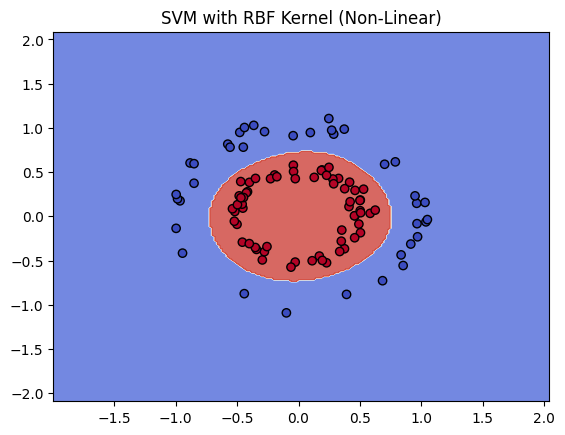

Accuracy: 100.00%


In [34]:
# Visualize
plot_decision_boundary(model,X_test, y_test)

print(f"Accuracy: {accuracy_score(y_test, model.predict(X_test))*100:.2f}%")